# Exploratory Data Analysis

## Undestanding the Data

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent
RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw"
PROC_DATA_PATH = PROJECT_ROOT / "data" / "processed"
RESULTS_PATH = PROJECT_ROOT / "results"

In [20]:
energy_path = RAW_DATA_PATH / "energy_nyc.csv"
energy = pd.read_csv(energy_path)
nyc_weather = pd.read_csv(RAW_DATA_PATH / "nyc_weather.csv")

In [21]:
energy = energy.rename(columns={"period": "time"})
energy["time"] = pd.to_datetime(energy["time"])
energy = energy.pivot(index=["time", "respondent", "respondent-name"], columns="type-name", values="value").reset_index()
energy.columns.name = None
energy = energy.drop(columns=["respondent-name"])
energy.head()

,time,respondent,Day-ahead demand forecast,Demand,Net generation,Total interchange
0,2022-01-01 00:00:00,NY,17215.0,18111.0,14636.0,-3475.0
1,2022-01-01 01:00:00,NY,16443.0,17580.0,14174.0,-3406.0
2,2022-01-01 02:00:00,NY,15713.0,17002.0,13807.0,-3195.0
3,2022-01-01 03:00:00,NY,15200.0,16415.0,13274.0,-3141.0
4,2022-01-01 04:00:00,NY,14903.0,15767.0,12485.0,-3282.0


In [29]:
nyc_weather = nyc_weather.rename(columns={"date": "time"})
nyc_weather["time"] = pd.to_datetime(nyc_weather["time"]).dt.tz_localize(None)
nyc_weather = nyc_weather.set_index("time")
nyc_weather.head()

,temperature_2m,relative_humidity_2m,apparent_temperature,precipitation,wind_speed_10m,surface_pressure
time,,,,,,
2022-01-01 00:00:00,9.631001,94.0,8.290460,0.0,6.877790,1010.4876
2022-01-01 01:00:00,9.631001,92.0,7.949134,0.0,8.647496,1010.0891
2022-01-01 02:00:00,9.581000,96.0,8.458690,0.0,5.860375,1010.0882
2022-01-01 03:00:00,9.881001,95.0,9.116524,0.0,3.671294,1009.8930
2022-01-01 04:00:00,9.831000,94.0,8.832214,0.0,4.896529,1009.6932


In [ ]:
print("Energy Data")
print("-"*30)
print(f"Duplicates = {energy.duplicated().sum()}")
print(f"Empty	   = {energy["Demand"].isna().sum().sum()}")
print("="*30)
print("Weather Data")
print("-"*30)
print(f"Duplicates = {nyc_weather.duplicated().sum()}")
print(f"Empty	   = {nyc_weather.isna().sum().sum()}")

Energy Data
------------------------------
Duplicates = 0
Empty	   = 0
Weather Data
------------------------------
Duplicates = 0
Empty	   = 0


In [107]:
nyc_weather.duplicated().sum()

np.int64(0)

## Trends in the Data - Energy

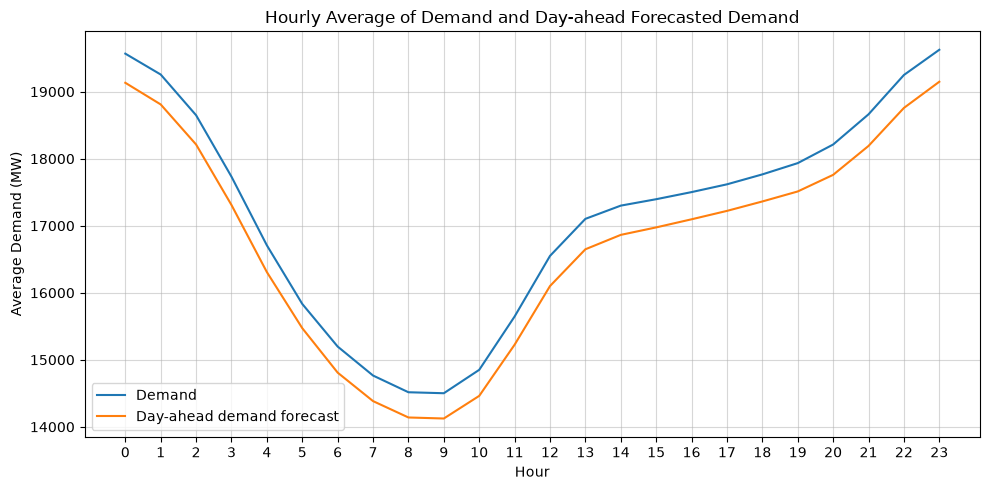

In [31]:
hours = energy["time"].dt.hour
hourly_avg = energy.groupby(hours).mean(numeric_only=True)
hourly_avg[["Demand", "Day-ahead demand forecast"]].plot(kind="line", figsize=(10, 5), rot=0)
plt.title("Hourly Average of Demand and Day-ahead Forecasted Demand")
plt.xlabel("Hour")
plt.ylabel("Average Demand (MW)")
plt.xticks(ticks=range(0, 24))
plt.grid(True, alpha=0.5)
plt.tight_layout()
plt.savefig(RESULTS_PATH / "plots" / "hourly_average_demands.png")
plt.show()

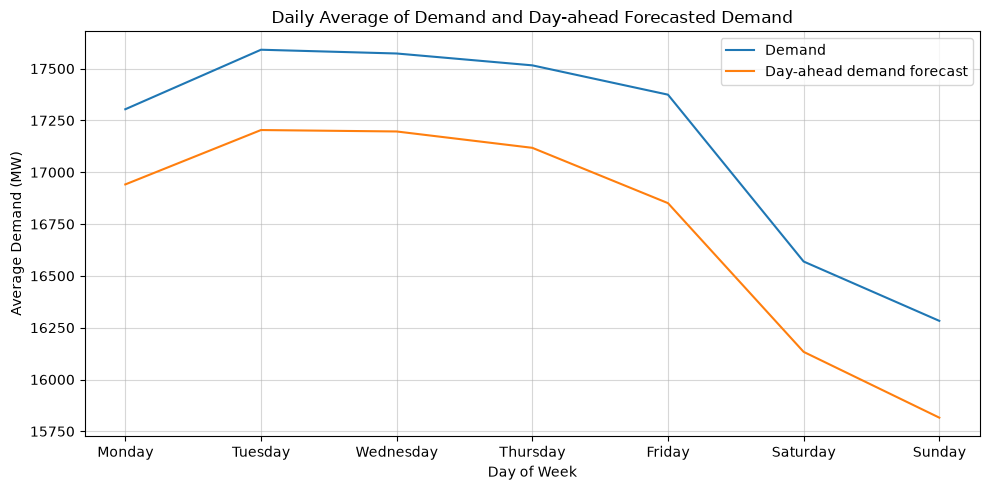

In [29]:
days = energy["time"].dt.dayofweek
day_names = energy["time"].dt.day_name()
daily_avg = energy.groupby([days, day_names]).mean(numeric_only=True).reset_index(level=0, drop=True)
daily_avg[["Demand", "Day-ahead demand forecast"]].plot(kind="line", figsize=(10, 5), rot=0)
plt.title("Daily Average of Demand and Day-ahead Forecasted Demand")
plt.xlabel("Day of Week")
plt.ylabel("Average Demand (MW)")
plt.grid(True, alpha=0.5)
plt.tight_layout()
plt.savefig(RESULTS_PATH / "plots" / "daily_average_demands.png")
plt.show()

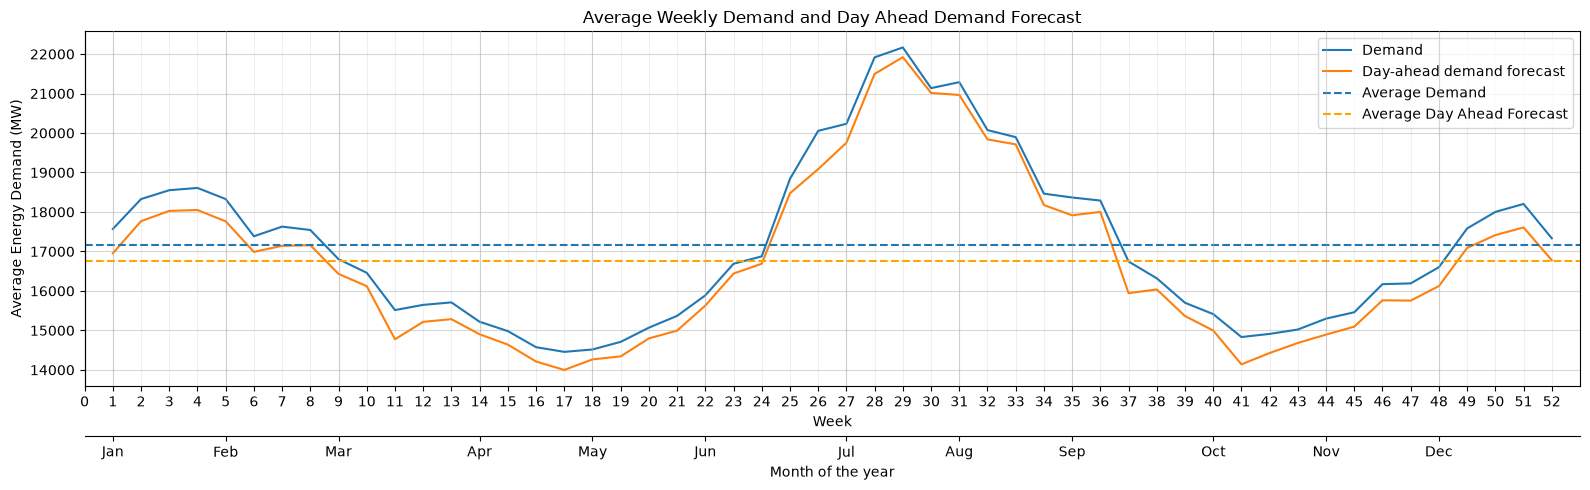

In [27]:
weeks = energy["time"].dt.isocalendar().week
weekly_avg = energy[["Demand", "Day-ahead demand forecast"]].groupby(weeks).mean()
fig, ax1 = plt.subplots(figsize=(16, 5))
weekly_avg.plot(kind="line", ax=ax1, rot=0)
ax1.set_xlim(0, 53)
ax1.set_xticks(range(0, 53, 1))
ax1.grid(True, axis="y", alpha=0.5)
ax1.grid(True, axis="x", alpha=0.2)
ax1.set_xlabel("Week")
ax1.set_ylabel("Average Energy Demand (MW)")
ax1.set_title("Average Weekly Demand and Day Ahead Demand Forecast")
ax1.axhline(y=energy["Demand"].mean(), linestyle="--", label="Average Demand")
ax1.axhline(y=energy["Day-ahead demand forecast"].mean(), linestyle="--", label="Average Day Ahead Forecast", color="orange")
ax1.legend()

ax2 = ax1.twiny()
ax2.set_xlim(ax1.get_xlim())
ax2.xaxis.set_ticks_position("bottom")
ax2.xaxis.set_label_position("bottom")
ax2.spines["bottom"].set_position(("outward", 36))
month_weeks = [1, 5, 9, 14, 18, 22, 27, 31, 35, 40, 44, 48]
month_labels = [
	"Jan",
	"Feb",
	"Mar",
	"Apr",
	"May",
	"Jun",
	"Jul",
	"Aug",
	"Sep",
	"Oct",
	"Nov",
	"Dec",
]
ax2.set_xticks(month_weeks)
ax2.set_xticklabels(month_labels)
ax2.set_xlabel("Month of the year")
ax2.grid(True, alpha=0.5)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
plt.tight_layout()
plt.savefig(RESULTS_PATH / "plots" / "weekly_average_demand.png")
plt.show()

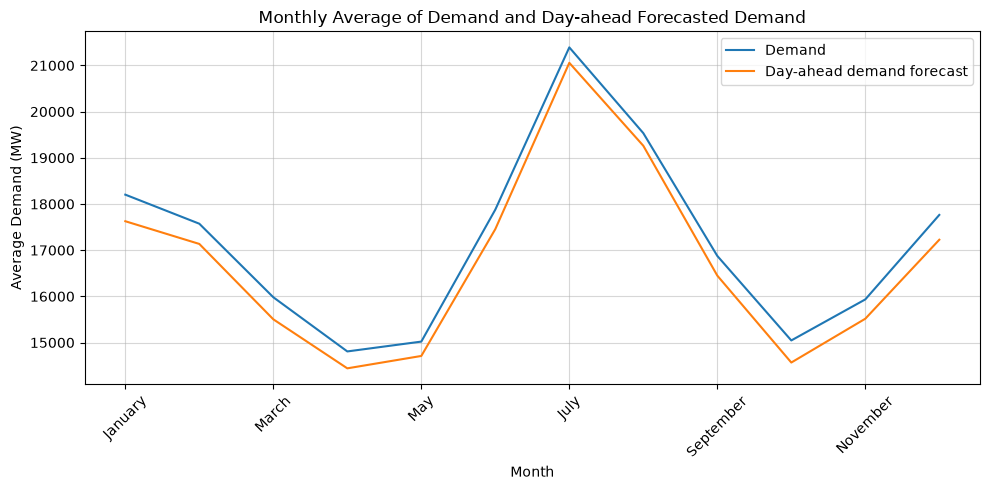

In [33]:
months = energy["time"].dt.month
month_names = energy["time"].dt.month_name()
monthly_avg = energy.groupby([months, month_names]).mean(numeric_only=True).reset_index(level=0, drop=True)
monthly_avg[["Demand", "Day-ahead demand forecast"]].plot(kind="line", figsize=(10, 5), rot=45)
plt.title("Monthly Average of Demand and Day-ahead Forecasted Demand")
plt.xlabel("Month")
plt.ylabel("Average Demand (MW)")
plt.grid(True, alpha=0.5)
plt.tight_layout()
plt.savefig(RESULTS_PATH / "plots" / "monthly_average_demands.png")
plt.show()

In [36]:
energy.to_csv(PROC_DATA_PATH / "energy_nyc.parquet", index=False)

## Trends in Data - Weather

In [33]:
same_scale = ['temperature_2m', 'relative_humidity_2m', 'apparent_temperature', 'precipitation', 'wind_speed_10m']
diff_scale = ['surface_pressure']

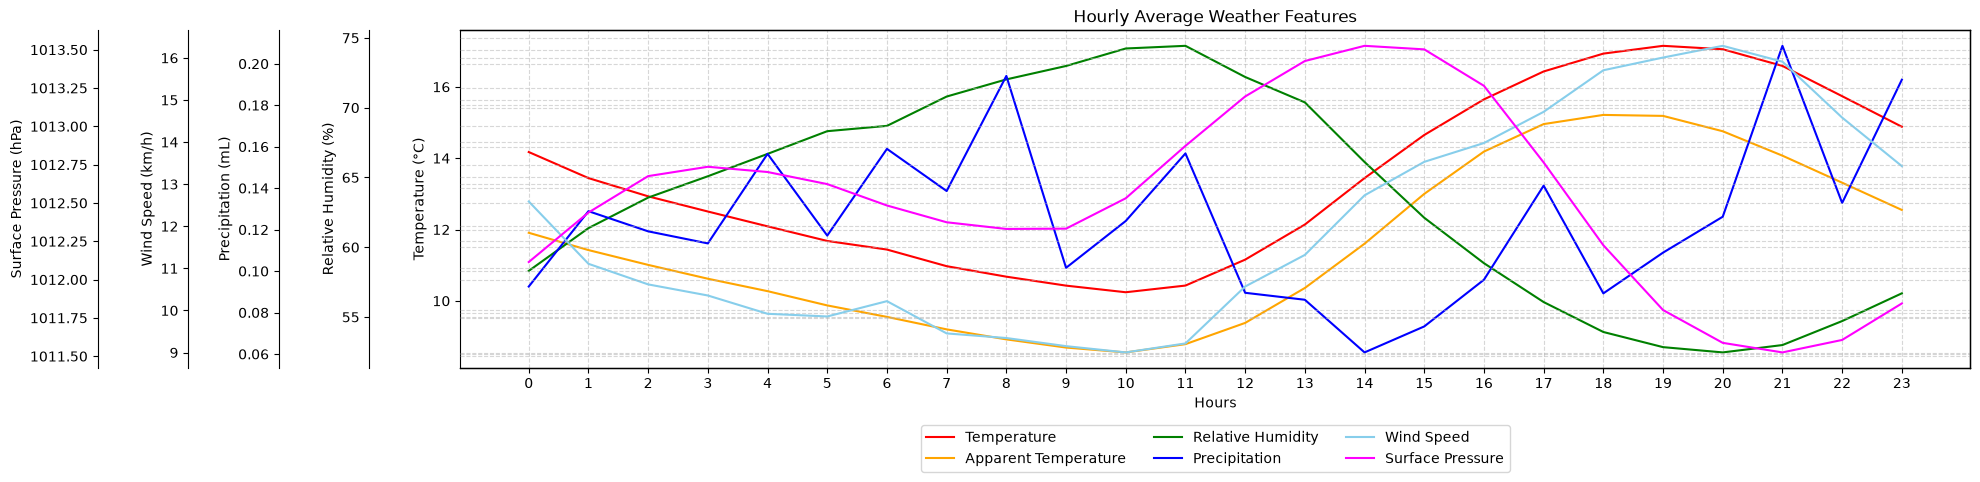

In [86]:
hours = nyc_weather.index.hour
hourly_avg = nyc_weather.groupby(hours).mean(numeric_only=True)
fig, ax1 = plt.subplots(figsize=(20, 5))
ax2 = ax1.twinx()
ax3 = ax1.twinx()
ax4 = ax1.twinx()
ax5 = ax1.twinx()

ax1.plot(hourly_avg.index, hourly_avg["temperature_2m"], label="Temperature", color="red")
ax1.plot(hourly_avg.index, hourly_avg["apparent_temperature"], label="Apparent Temperature", color="orange")
ax1.set_xlabel("Hours")
ax1.set_ylabel("Temperature (°C)")
ax1.set_xticks(ticks=range(0, 24))
ax1.grid(axis="x", linestyle="--", alpha=0.5)

ax2.yaxis.set_ticks_position("left")
ax2.yaxis.set_label_position("left")
ax2.spines.left.set_position(("axes", -0.06))
ax2.plot(hourly_avg.index, hourly_avg["relative_humidity_2m"], label="Relative Humidity", color="green")
ax2.set_ylabel("Relative Humidity (%)")
ax2.grid(axis="y", linestyle="--", alpha=0.5)

ax3.yaxis.set_ticks_position("left")
ax3.yaxis.set_label_position("left")
ax3.spines.left.set_position(("axes", -0.12))
ax3.plot(hourly_avg.index, hourly_avg["precipitation"], label="Precipitation", color="blue")
ax3.set_ylabel("Precipitation (mL)")
ax3.grid(axis="y", linestyle="--", alpha=0.5)

ax4.yaxis.set_ticks_position("left")
ax4.yaxis.set_label_position("left")
ax4.spines.left.set_position(("axes", -0.18))
ax4.plot(hourly_avg.index, hourly_avg["wind_speed_10m"], label="Wind Speed", color="skyblue")
ax4.set_ylabel("Wind Speed (km/h)")
ax4.grid(axis="y", linestyle="--", alpha=0.5)

ax5.yaxis.set_ticks_position("left")
ax5.yaxis.set_label_position("left")
ax5.spines.left.set_position(("axes", -0.24))
ax5.plot(hourly_avg.index, hourly_avg["surface_pressure"], label="Surface Pressure", color="magenta")
ax5.set_ylabel("Surface Pressure (hPa)")
ax5.grid(axis="y", linestyle="--", alpha=0.5)

lines = ax1.get_lines() + ax2.get_lines() + ax3.get_lines() + ax4.get_lines() + ax5.get_lines()
labels = [line.get_label() for line in lines]
ax1.legend(lines, labels, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncols=3)
plt.title("Hourly Average Weather Features")
plt.tight_layout()
plt.savefig(RESULTS_PATH / "plots" / "hourly_average_weather.png")
plt.show()

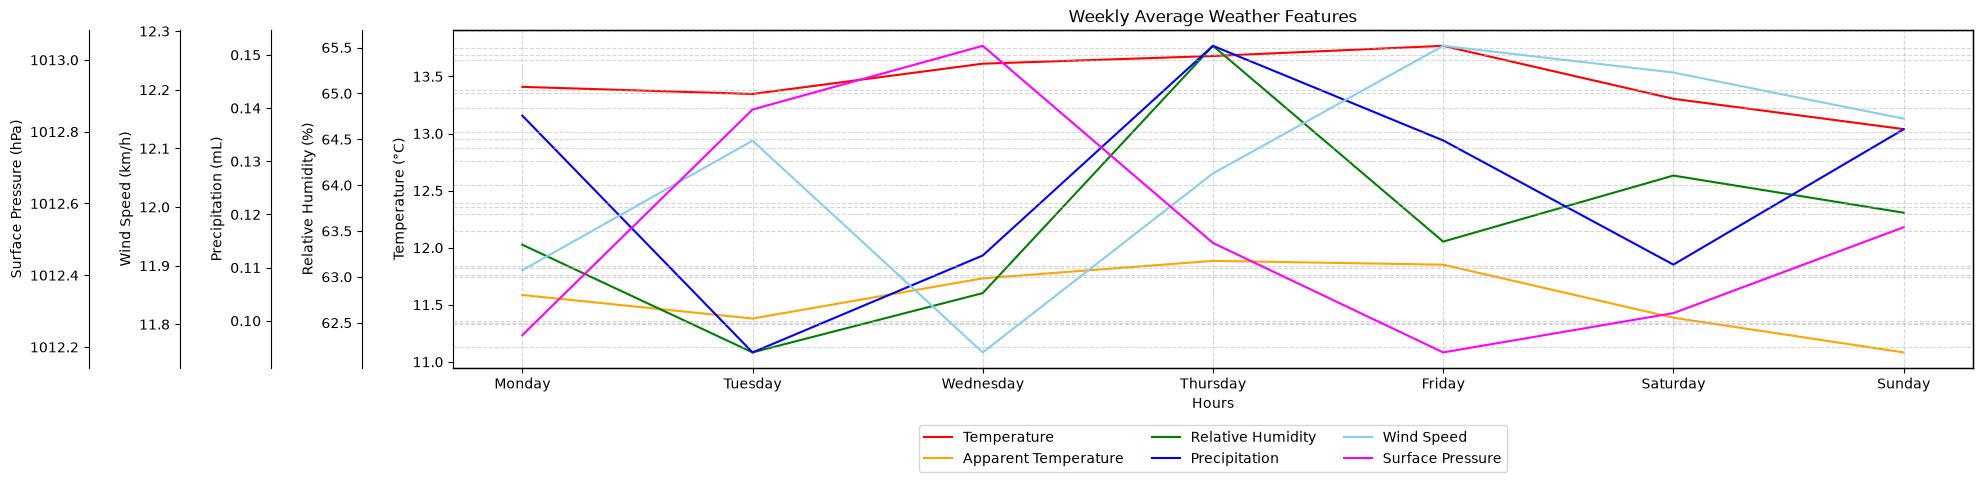

In [103]:
days = nyc_weather.index.dayofweek
day_names = nyc_weather.index.day_name()
daily_avg = nyc_weather.groupby([days, day_names]).mean(numeric_only=True).reset_index(level=0, drop=True)

fig, ax1 = plt.subplots(figsize=(20, 5))
ax2 = ax1.twinx()
ax3 = ax1.twinx()
ax4 = ax1.twinx()
ax5 = ax1.twinx()

ax1.plot(daily_avg.index, daily_avg["temperature_2m"], label="Temperature", color="red")
ax1.plot(daily_avg.index, daily_avg["apparent_temperature"], label="Apparent Temperature", color="orange")
ax1.set_xlabel("Hours")
ax1.set_ylabel("Temperature (°C)")
ax1.grid(axis="x", linestyle="--", alpha=0.5)

ax2.yaxis.set_ticks_position("left")
ax2.yaxis.set_label_position("left")
ax2.spines.left.set_position(("axes", -0.06))
ax2.plot(daily_avg.index, daily_avg["relative_humidity_2m"], label="Relative Humidity", color="green")
ax2.set_ylabel("Relative Humidity (%)")
ax2.grid(axis="y", linestyle="--", alpha=0.5)

ax3.yaxis.set_ticks_position("left")
ax3.yaxis.set_label_position("left")
ax3.spines.left.set_position(("axes", -0.12))
ax3.plot(daily_avg.index, daily_avg["precipitation"], label="Precipitation", color="blue")
ax3.set_ylabel("Precipitation (mL)")
ax3.grid(axis="y", linestyle="--", alpha=0.5)

ax4.yaxis.set_ticks_position("left")
ax4.yaxis.set_label_position("left")
ax4.spines.left.set_position(("axes", -0.18))
ax4.plot(daily_avg.index, daily_avg["wind_speed_10m"], label="Wind Speed", color="skyblue")
ax4.set_ylabel("Wind Speed (km/h)")
ax4.grid(axis="y", linestyle="--", alpha=0.5)

ax5.yaxis.set_ticks_position("left")
ax5.yaxis.set_label_position("left")
ax5.spines.left.set_position(("axes", -0.24))
ax5.plot(daily_avg.index, daily_avg["surface_pressure"], label="Surface Pressure", color="magenta")
ax5.set_ylabel("Surface Pressure (hPa)")
ax5.grid(axis="y", linestyle="--", alpha=0.5)

lines = ax1.get_lines() + ax2.get_lines() + ax3.get_lines() + ax4.get_lines() + ax5.get_lines()
labels = [line.get_label() for line in lines]
ax1.legend(lines, labels, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncols=3)
plt.title("Weekly Average Weather Features")
plt.tight_layout()
plt.savefig(RESULTS_PATH / "plots" / "daily_average_weather.png")
plt.show()

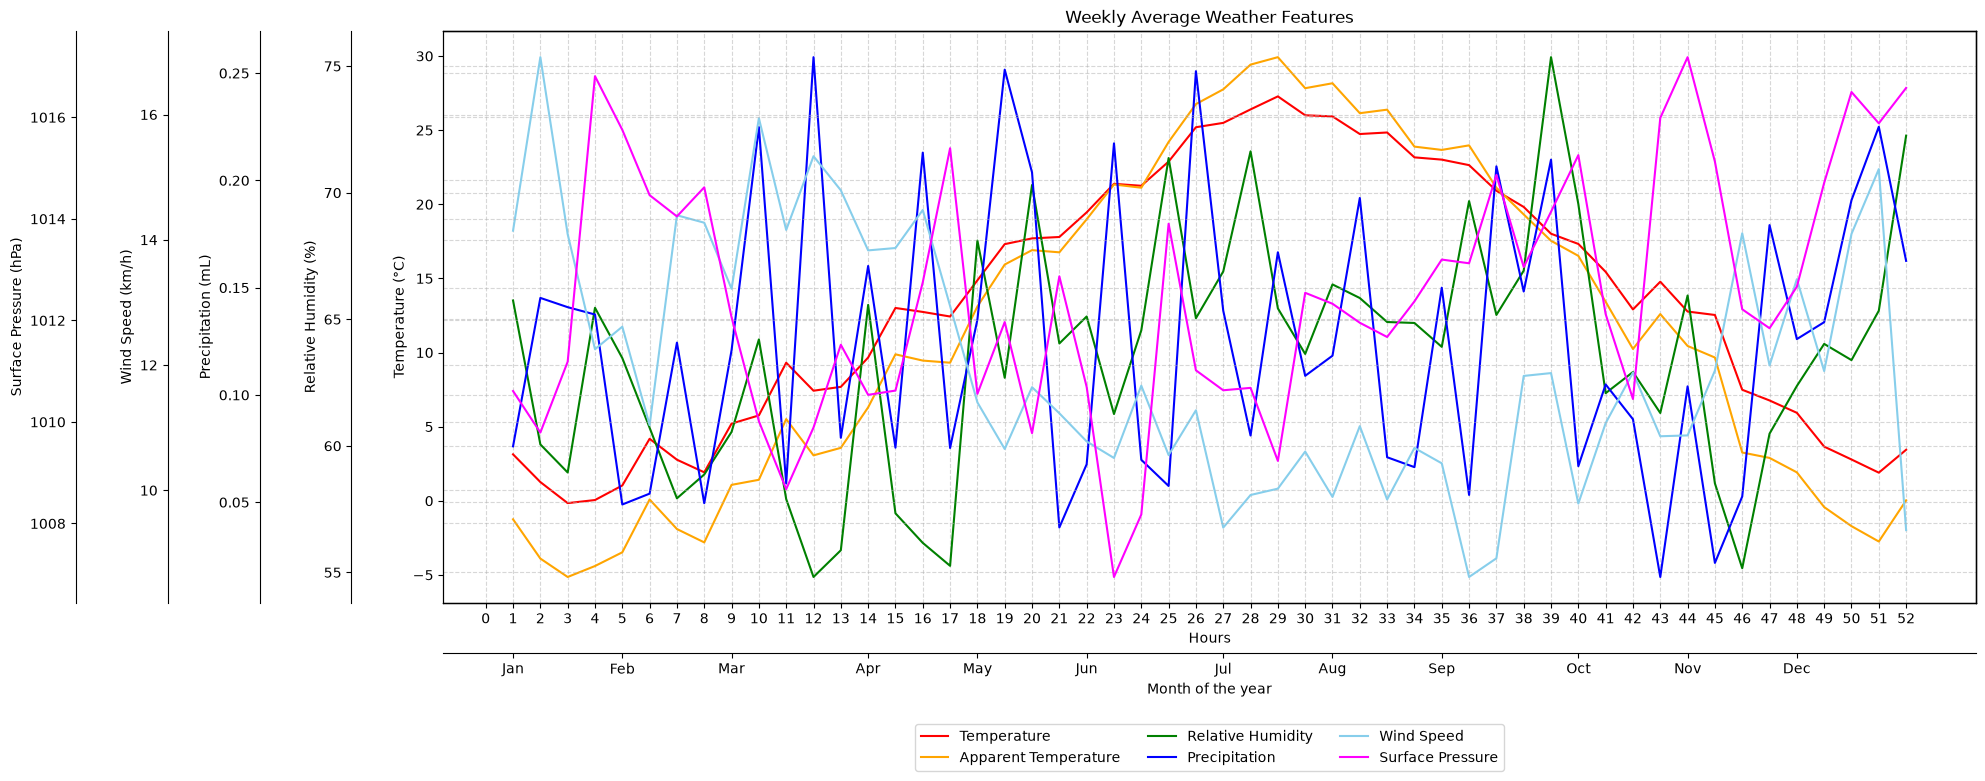

In [104]:
weeks = nyc_weather.index.isocalendar().week
weekly_avg = nyc_weather.groupby(weeks).mean()

fig, ax1 = plt.subplots(figsize=(20, 8))
ax2 = ax1.twinx()
ax3 = ax1.twinx()
ax4 = ax1.twinx()
ax5 = ax1.twinx()

ax1.plot(weekly_avg.index, weekly_avg["temperature_2m"], label="Temperature", color="red")
ax1.plot(weekly_avg.index, weekly_avg["apparent_temperature"], label="Apparent Temperature", color="orange")
ax1.set_xlabel("Hours")
ax1.set_ylabel("Temperature (°C)")
ax1.set_xticks(range(0, 53, 1))
ax1.grid(axis="x", linestyle="--", alpha=0.5)

ax2.yaxis.set_ticks_position("left")
ax2.yaxis.set_label_position("left")
ax2.spines.left.set_position(("axes", -0.06))
ax2.plot(weekly_avg.index, weekly_avg["relative_humidity_2m"], label="Relative Humidity", color="green")
ax2.set_ylabel("Relative Humidity (%)")
ax2.grid(axis="y", linestyle="--", alpha=0.5)

ax3.yaxis.set_ticks_position("left")
ax3.yaxis.set_label_position("left")
ax3.spines.left.set_position(("axes", -0.12))
ax3.plot(weekly_avg.index, weekly_avg["precipitation"], label="Precipitation", color="blue")
ax3.set_ylabel("Precipitation (mL)")
ax3.grid(axis="y", linestyle="--", alpha=0.5)

ax4.yaxis.set_ticks_position("left")
ax4.yaxis.set_label_position("left")
ax4.spines.left.set_position(("axes", -0.18))
ax4.plot(weekly_avg.index, weekly_avg["wind_speed_10m"], label="Wind Speed", color="skyblue")
ax4.set_ylabel("Wind Speed (km/h)")
ax4.grid(axis="y", linestyle="--", alpha=0.5)

ax5.yaxis.set_ticks_position("left")
ax5.yaxis.set_label_position("left")
ax5.spines.left.set_position(("axes", -0.24))
ax5.plot(weekly_avg.index, weekly_avg["surface_pressure"], label="Surface Pressure", color="magenta")
ax5.set_ylabel("Surface Pressure (hPa)")
ax5.grid(axis="y", linestyle="--", alpha=0.5)

axx = ax1.twiny()
axx.set_xlim(ax1.get_xlim())
axx.xaxis.set_ticks_position("bottom")
axx.xaxis.set_label_position("bottom")
axx.spines["bottom"].set_position(("outward", 36))
month_weeks = [1, 5, 9, 14, 18, 22, 27, 31, 35, 40, 44, 48]
month_labels = [
	"Jan",
	"Feb",
	"Mar",
	"Apr",
	"May",
	"Jun",
	"Jul",
	"Aug",
	"Sep",
	"Oct",
	"Nov",
	"Dec",
]
axx.set_xticks(month_weeks)
axx.set_xticklabels(month_labels)
axx.set_xlabel("Month of the year")

lines = ax1.get_lines() + ax2.get_lines() + ax3.get_lines() + ax4.get_lines() + ax5.get_lines()
labels = [line.get_label() for line in lines]
ax1.legend(lines, labels, loc="upper center", bbox_to_anchor=(0.5, -0.20), ncols=3)
plt.title("Weekly Average Weather Features")
plt.tight_layout()
plt.savefig(RESULTS_PATH / "plots" / "weekly_average_weather.png")
plt.show()

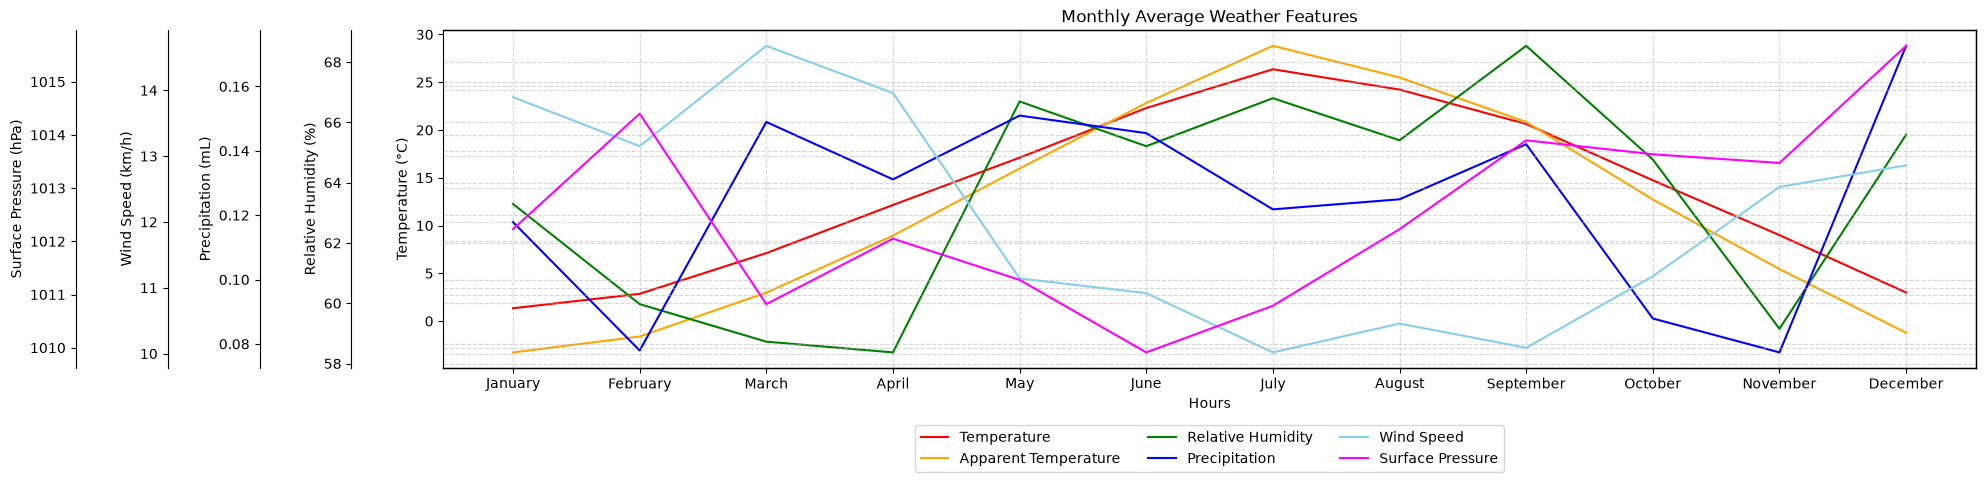

In [106]:
months = nyc_weather.index.month
month_names = nyc_weather.index.month_name()
monthly_avg = nyc_weather.groupby([months, month_names]).mean(numeric_only=True).reset_index(level=0, drop=True)

fig, ax1 = plt.subplots(figsize=(20, 5))
ax2 = ax1.twinx()
ax3 = ax1.twinx()
ax4 = ax1.twinx()
ax5 = ax1.twinx()

ax1.plot(monthly_avg.index, monthly_avg["temperature_2m"], label="Temperature", color="red")
ax1.plot(monthly_avg.index, monthly_avg["apparent_temperature"], label="Apparent Temperature", color="orange")
ax1.set_xlabel("Hours")
ax1.set_ylabel("Temperature (°C)")
ax1.grid(axis="x", linestyle="--", alpha=0.5)

ax2.yaxis.set_ticks_position("left")
ax2.yaxis.set_label_position("left")
ax2.spines.left.set_position(("axes", -0.06))
ax2.plot(monthly_avg.index, monthly_avg["relative_humidity_2m"], label="Relative Humidity", color="green")
ax2.set_ylabel("Relative Humidity (%)")
ax2.grid(axis="y", linestyle="--", alpha=0.5)

ax3.yaxis.set_ticks_position("left")
ax3.yaxis.set_label_position("left")
ax3.spines.left.set_position(("axes", -0.12))
ax3.plot(monthly_avg.index, monthly_avg["precipitation"], label="Precipitation", color="blue")
ax3.set_ylabel("Precipitation (mL)")
ax3.grid(axis="y", linestyle="--", alpha=0.5)

ax4.yaxis.set_ticks_position("left")
ax4.yaxis.set_label_position("left")
ax4.spines.left.set_position(("axes", -0.18))
ax4.plot(monthly_avg.index, monthly_avg["wind_speed_10m"], label="Wind Speed", color="skyblue")
ax4.set_ylabel("Wind Speed (km/h)")
ax4.grid(axis="y", linestyle="--", alpha=0.5)

ax5.yaxis.set_ticks_position("left")
ax5.yaxis.set_label_position("left")
ax5.spines.left.set_position(("axes", -0.24))
ax5.plot(monthly_avg.index, monthly_avg["surface_pressure"], label="Surface Pressure", color="magenta")
ax5.set_ylabel("Surface Pressure (hPa)")
ax5.grid(axis="y", linestyle="--", alpha=0.5)

lines = ax1.get_lines() + ax2.get_lines() + ax3.get_lines() + ax4.get_lines() + ax5.get_lines()
labels = [line.get_label() for line in lines]
ax1.legend(lines, labels, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncols=3)
plt.title("Monthly Average Weather Features")
plt.tight_layout()
plt.savefig(RESULTS_PATH / "plots" / "monthly_average_weather.png")
plt.show()